In [ ]:
#2D
import numpy as np
rng=np.random.default_rng(0)
N=12 #no of particles
L=10.0 #box side length
dt=0.01 #time step
T=1000 #no of simulation steps
mass=np.ones(N)
vel=rng.random(size=(N,2))-0.5
low,high=0,10
precision=10**6
pos=low+(high-low)*(rng.integers(0,precision,size=(N,2),endpoint=True)/precision)
print(pos.shape,':shape of pos')
print(vel.shape,': shape of vel')
print(pos.dtype,':for pos matrix')
print(pos.itemsize,': datasize for float64',' ,matches what we would expect from sizeof(double) in C')
pos32=pos.astype(np.float32)
print(pos32.dtype,': for pos 32 matrix')
print(pos32.itemsize,': datasize for float32',' ,matches what we would expect from sizeof(float) in C')
print(pos.nbytes,': bytes if stored as float64')
print(pos32.nbytes,': bytes if stored as float32')
print('float32 takes less memory by a diff of:',int(pos.nbytes)-int(pos32.nbytes),',which is by a factor of:',int(pos32.nbytes)/int(pos.nbytes))
print('''A large simulation would prefer float32 over float64 for efficient memory allocation
  as seen using float32 reduces memory storage needed by x1/2
  however the tradeoff would be a loss in desired precision and prone to effects like catastrophic cancellation.''')

print(pos,'and',vel)

(12, 2) :shape of pos
(12, 2) : shape of vel
float64 :for pos matrix
8 : datasize for float64  ,matches what we would expect from sizeof(double) in C
float32 : for pos 32 matrix
4 : datasize for float32  ,matches what we would expect from sizeof(float) in C
192 : bytes if stored as float64
96 : bytes if stored as float32
float32 takes less memory by a diff of: 96 ,which is by a factor of: 0.5
A large simulation would prefer float32 over float64 for efficient memory allocation
  as seen using float32 reduces memory storage needed by x1/2
  however the tradeoff would be a loss in desired precision and prone to effects like catastrophic cancellation.
[[2.573   6.15385]
 [7.64055 3.83677]
 [4.60922 9.9721 ]
 [8.04989 9.80836]
 [3.79523 6.85542]
 [9.50101 6.50459]
 [8.40312 6.88447]
 [7.04001 3.88921]
 [8.75157 1.35096]
 [5.78904 7.21489]
 [8.45481 5.25354]
 [3.75417 3.10242]] and [[ 0.13696169 -0.23021329]
 [-0.45902648 -0.48347236]
 [ 0.31327024  0.41275558]
 [ 0.10663578  0.22949656]
 [ 

In [ ]:
# wall reflections
#lets make impact with wall have coefficient or restitution as 'e'
print(pos,'and',vel)
e_input = 1
def wall_reflection(pos,vel,L,e=1.0):
    #Left wall, x<0
    left_hits=pos[:,0]<0
    vel[left_hits,0]*= -e
    pos[left_hits,0]=0.0
    #Right wall, x>L
    right_hits=pos[:,0]>L
    vel[right_hits,0]*=-e
    pos[right_hits,0]=L
    #Bottom wal, y<0
    bottom_hits=pos[:,1]<0
    vel[bottom_hits,1]*=-e
    pos[bottom_hits,1]=0.0
    #Top wall, y>l
    top_hits=pos[:,1]>L
    vel[top_hits,1]*=-e
    pos[top_hits,1]=L

    return pos,vel
wall_reflection(pos,vel,L)
#Test
tpos=np.array([[L+0.1,5]])
tvel=np.array([[0.33,0.88]])
tpos,tvel=wall_reflection(tpos,tvel,L,e_input)
print("Wall reflection test -> pos:", tpos[0, 0], "| vel:", tvel[0, 0])
tpos=np.array([[-0.03,5]])
tvel=np.array([[-0.5,0.81]])
tpos,tvel=wall_reflection(tpos,tvel,L,e_input)
print("Wall reflection test -> pos:", tpos[0, 0], "| vel:", tvel[0, 0])
tpos=np.array([[6.8,L+0.2]])
tvel=np.array([[0.65,-3.88]])
tpos,tvel=wall_reflection(tpos,tvel,L,e_input)
print("Wall reflection test -> pos:", tpos[0, 1], "| vel:", tvel[0, 1])
tpos=np.array([[4.9,-0.05]])
tvel=np.array([[-0.3,-7.8]])
tpos,tvel=wall_reflection(tpos,tvel,L,e_input)
print("Wall reflection test -> pos:", tpos[0, 1], "| vel:", tvel[0, 1])

[[2.573   6.15385]
 [7.64055 3.83677]
 [4.60922 9.9721 ]
 [8.04989 9.80836]
 [3.79523 6.85542]
 [9.50101 6.50459]
 [8.40312 6.88447]
 [7.04001 3.88921]
 [8.75157 1.35096]
 [5.78904 7.21489]
 [8.45481 5.25354]
 [3.75417 3.10242]] and [[ 0.13696169 -0.23021329]
 [-0.45902648 -0.48347236]
 [ 0.31327024  0.41275558]
 [ 0.10663578  0.22949656]
 [ 0.04362499  0.43507242]
 [ 0.31585355 -0.4972615 ]
 [ 0.35740428 -0.46641442]
 [ 0.22965545 -0.32434438]
 [ 0.36317892  0.04146122]
 [-0.20028811 -0.07731278]
 [-0.47168033 -0.37571672]
 [ 0.17062441  0.14718951]]
Wall reflection test -> pos: 10.0 | vel: -0.33
Wall reflection test -> pos: 0.0 | vel: 0.5
Wall reflection test -> pos: 10.0 | vel: 3.88
Wall reflection test -> pos: 0.0 | vel: 7.8


In [ ]:
#pairwise distance calculation
import pandas as pd
r_c=2.0#cutoff distance
def pairwise_dist(pos,r_c):
    N=pos.shape[0]# returns no of rows in 2D case, and sheet no in 3D case
    d=pos[:,None,:]-pos[None,:,:]
    dist=np.sum(np.power(d,2),axis=-1)**(1/2)
    neighbors=(dist>0)&(dist<=r_c)
    return d,dist,neighbors


In [ ]:
def view(dist,neighbors):
    labels=[f"P{i}"for i in range(len(pos))]
    df_dist=pd.DataFrame(dist,index=labels,columns=labels).round(2)
    df_neighbors=pd.DataFrame(neighbors,index=labels,columns=labels)
    print("--- Distance Matrix ---")
    print(df_dist)
    print("\n--- Boolean Neighbor Matrix ---")
    print(df_neighbors)
d,dist,neighbors=pairwise_dist(pos,r_c)
print('Clearly the dist matrix is symmetric as distance between A and B = distance between B and A')
print("Also the diagonal elements are 0, as the distance of a particle from itself =0")
print('hence the neighbors matrix for sure has \'False\' for all its diagonal elements')
view(dist,neighbors)
no_of_nb=np.sum(neighbors, axis=1)
print(no_of_nb)

Clearly the dist matrix is symmetric as distance between A and B = distance between B and A
Also the diagonal elements are 0, as the distance of a particle from itself =0
hence the neighbors matrix for sure has 'False' for all its diagonal elements
--- Distance Matrix ---
       P0    P1    P2    P3    P4    P5    P6    P7    P8    P9   P10   P11
P0   0.00  5.57  4.33  6.58  1.41  6.94  5.88  5.01  7.83  3.39  5.95  3.27
P1   5.57  0.00  6.84  5.99  4.89  3.25  3.14  0.60  2.72  3.85  1.63  3.96
P2   4.33  6.84  0.00  3.44  3.22  6.00  4.89  6.55  9.56  3.00  6.09  6.92
P3   6.58  5.99  3.44  0.00  5.18  3.61  2.95  6.00  8.49  3.44  4.57  7.96
P4   1.41  4.89  3.22  5.18  0.00  5.72  4.61  4.40  7.41  2.03  4.93  3.75
P5   6.94  3.25  6.00  3.61  5.72  0.00  1.16  3.59  5.21  3.78  1.63  6.68
P6   5.88  3.14  4.89  2.95  4.61  1.16  0.00  3.29  5.54  2.63  1.63  5.99
P7   5.01  0.60  6.55  6.00  4.40  3.59  3.29  0.00  3.06  3.55  1.97  3.38
P8   7.83  2.72  9.56  8.49  7.41  5.21  5.

In [ ]:
#Test
pos_4 = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 2.0], [10.0, 10.0]])
rc1=2.0
D1,DIST1,NEIGHBOR1=pairwise_dist(pos_4,rc1)
print('neighbor count for pos_4 for cutoff 2.0:',np.sum(NEIGHBOR1,axis=1))
print("--- 4-particle sanity checks ---")
print("Distance matrix is symmetric:",np.allclose(DIST1,DIST1.T))
print("Diagonals are 0:",np.all(np.diag(DIST1)==0))
print("Neighbors matrix yields false for diagonal elements:",not NEIGHBOR1.diagonal().any())
rc2=3.0
D2,DIST2,NEIGHBOR2=pairwise_dist(pos_4,rc2)
print('neighbor count for pos_4 for cutoff 3.0:',np.sum(NEIGHBOR2,axis=1))
print("--- 4-particle sanity checks ---")
print("Distance matrix is symmetric:",np.allclose(DIST2,DIST2.T))
print("Diagonals are 0:",np.all(np.diag(DIST2)==0))
print("Neighbors matrix yields false for diagonal elements:",not NEIGHBOR2.diagonal().any())
print('avg no of neighbors per particle for a 200 particle test:')
def avg(nb):
    return sum(nb)/200
pos_test=(50)*(rng.integers(0,precision,size=(200,2),endpoint=True)/precision)
r_c2=2.0 #cutoff distance
d2,dist2,neighbors2=pairwise_dist(pos_test,r_c2)
no_of_nb2=np.sum(neighbors2, axis=1)
print(avg(no_of_nb2), 'for a cutoff of:',r_c2)
r_c3=2.5
d3,dist3,neighbors3=pairwise_dist(pos_test,r_c3)
no_of_nb3=np.sum(neighbors3, axis=1)
print(avg(no_of_nb3), 'for a cutoff of:',r_c3)
r_c4=1.8
d4,dist4,neighbors4=pairwise_dist(pos_test,r_c4)
no_of_nb4=np.sum(neighbors4, axis=1)
print(avg(no_of_nb4), 'for a cutoff of:',r_c4)
r_c5=5.2
d5,dist5,neighbors5=pairwise_dist(pos_test,r_c5)
no_of_nb5=np.sum(neighbors5, axis=1)
print(avg(no_of_nb5), 'for a cutoff of:',r_c5)

neighbor count for pos_4 for cutoff 2.0: [2 1 1 0]
--- 4-particle sanity checks ---
Distance matrix is symmetric: True
Diagonals are 0: True
Neighbors matrix yields false for diagonal elements: True
neighbor count for pos_4 for cutoff 3.0: [2 2 2 0]
--- 4-particle sanity checks ---
Distance matrix is symmetric: True
Diagonals are 0: True
Neighbors matrix yields false for diagonal elements: True
avg no of neighbors per particle for a 200 particle test:
0.93 for a cutoff of: 2.0
1.47 for a cutoff of: 2.5
0.75 for a cutoff of: 1.8
5.86 for a cutoff of: 5.2


In [ ]:
#Springs between particles
import time as t
k = 15.0
r0 = 0.8

def pair_forces(pos):
    F = np.zeros_like(pos)#creates a 0 filled array that matches the exact shape and dtype of 'pos'
    d, dist, neighbors = pairwise_dist(pos, r_c)
    for i in range(pos.shape[0]):
        for j in range(i+1,pos.shape[0]):#loops only unique pairs where j>i
            if neighbors[i,j]:
                mag_force=k*(dist[i,j]-r0)#v=A-B vector points from tip B to tip A
                dir_force=d[i,j]/dist[i,j]#d[i,j] points from particle j to i, since d=pos[:,None,:]-pos[None,:,:], which implies d[i,j]=pos[i]-pos[j]
                f_vec=(-1)*mag_force*dir_force#ensures force on particle i points back toward j
                F[i]+=f_vec
                F[j]-=f_vec#3rd law, force on i is opp and same magn as force on j
    return F

print(pair_forces(pos))
print(np.sum(pair_forces(pos),axis=0))
print("Clearly third law is followed as net sum of Fx and Fy vectors are negligible, very close to 0")


[[  7.92611668   4.54965569]
 [  9.18076879  10.59017532]
 [  0.           0.        ]
 [  0.           0.        ]
 [ -7.92611668  -4.54965569]
 [-13.12292229  -7.7860085 ]
 [  5.52322802 -14.24431082]
 [  9.63763733  12.39242251]
 [  0.           0.        ]
 [  0.           0.        ]
 [-11.21871184  -0.95227852]
 [  0.           0.        ]]
[-3.55271368e-15  0.00000000e+00]
Clearly third law is followed as net sum of Fx and Fy vectors are negligible, very close to 0


In [ ]:
%%writefile pairforce.c
#include <math.h>
#ifdef STANDALONE
#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#endif
//math imported to use sqrt()
/* double* array refers to a pointer, basically pointer variable stores the mem address of pos rather than the whole array
, and any changes made to this pos will be reflected in the original pos. This allows for efficient handling of large arrays.
Without a pointer copying is required.*/
/* In F[i*2], * rep mutiplication operator, since C cant handle 2D arrays cleanly, it helps flatten them out in a single 1D array say pos[i*2]= [x0,y0,x1,y1...]
pos[i*2] would give x coord of particle i, and pos[i*2+1] the y coord.*/
// Computes 2D spring forces using a double loop
void pair_forces_c(double* pos, double* F, int N, double k, double r0, double rc) {
    // Initialize forces to 0
    for (int i = 0; i < N * 2; i++) {
        F[i] = 0.0;
    }

    for (int i = 0; i < N; i++) {
        for (int j = i + 1; j < N; j++) {
            double dx = pos[i * 2] - pos[j * 2];
            double dy = pos[i * 2 + 1] - pos[j * 2 + 1];
            double dist = sqrt(dx * dx + dy * dy);

            if (dist < rc && dist > 0.0) {
                double mag_force = k * (dist - r0);
                double fx = -mag_force * (dx / dist);
                double fy = -mag_force * (dy / dist);

                F[i * 2] += fx;
                F[i * 2 + 1] += fy;
                F[j * 2] -= fx;
                F[j * 2 + 1] -= fy;
            }
        }
    }
}
#ifdef STANDALONE
int main(void) {
    int    N = 1000;                      /* hardcoded parameters */
    double k = 15.0, r0 = 0.8, rc = 2.0, L = 10.0;
    double *pos = malloc(N * 2 * sizeof(double));
    double *F   = malloc(N * 2 * sizeof(double));
    srand(0);
    for (int i = 0; i < N * 2; i++) pos[i] = L * ((double)rand() / RAND_MAX);

    clock_t t0 = clock();
    pair_forces_c(pos, F, N, k, r0, rc);
    double secs = (double)(clock() - t0) / CLOCKS_PER_SEC;

    double sx = 0.0, sy = 0.0;
    for (int i = 0; i < N; i++) { sx += F[i*2]; sy += F[i*2+1]; }
    printf("N = %d, time = %.6f s\n", N, secs);
    printf("F[0] = (%.4f, %.4f)\n", F[0], F[1]);
    printf("sum of forces = (%.2e, %.2e)  <- should be ~0\n", sx, sy);
    free(pos); free(F);
    return 0;
}
#endif

Writing pairforce.c


In [ ]:
!gcc -shared -fPIC -O0 -lm -o libpairforce_O0.so pairforce.c
!gcc -shared -fPIC -O2 -lm -o libpairforce_O2.so pairforce.c
!gcc -O2 -DSTANDALONE -o pairforce pairforce.c -lm
!./pairforce

N = 1000, time = 0.003487 s
F[0] = (-71.0359, 7.6757)
sum of forces = (2.13e-13, 9.09e-13)  <- should be ~0


np.allclose(A,B) yields true if the 2 floats A and B are different from each other by a small tolerance (by default about 1e-8 relative and 1e-5 absolute)
. As across all the particle counts it yields true, this clearly implies that the 3 versions are equivalent
True True
True True
True True
True True


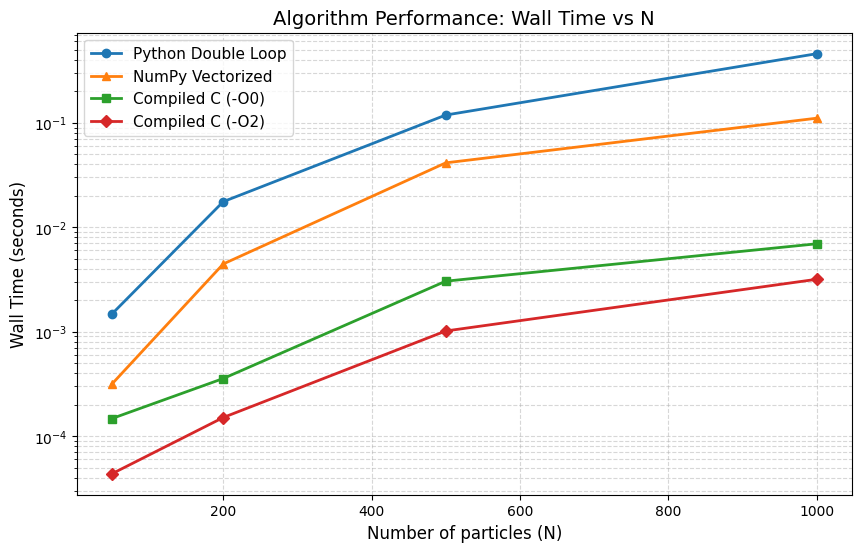

Fastest to slowest: C -O2 > C -O0 > NumPy vectorized > Python loop.Compiled C runs native machine code with no per-iteration interpreter overhead,
 and -O2 optimizes further than -O0; NumPy pushes the loops into compiled C too, but it builds full N x N temporary arrays
  (about twice the pair work), while the Python loop pays interpreter cost on every one of its N(N-1)/2 iterations.


In [ ]:
import numpy as np
import time
import ctypes
import matplotlib.pyplot as plt
from numpy.ctypeslib import ndpointer


lib_O0 = ctypes.CDLL('./libpairforce_O0.so')
lib_O2 = ctypes.CDLL('./libpairforce_O2.so')


for lib in [lib_O0, lib_O2]:
    lib.pair_forces_c.argtypes = [
        ndpointer(ctypes.c_double, flags="C_CONTIGUOUS"), # pos
        ndpointer(ctypes.c_double, flags="C_CONTIGUOUS"), # F
        ctypes.c_int, ctypes.c_double, ctypes.c_double, ctypes.c_double
    ]


def run_c_func(lib_func, pos, k=15.0, r0=0.8, r_c=2.0):
    """Wrapper to safely call the C functions"""
    N = pos.shape[0]
    pos_c = np.ascontiguousarray(pos, dtype=np.float64)
    F_c = np.zeros_like(pos_c)
    lib_func(pos_c, F_c, N, ctypes.c_double(k), ctypes.c_double(r0), ctypes.c_double(r_c))
    return F_c

def pair_forces_vectorized(pos, k=15.0, r0=0.8, r_c=2.0):
    """Wraps vectorized cell logic into a callable function"""
    d, dist, neighbors = pairwise_dist(pos, r_c)
    u = d / (dist[:, :, None] + 1e-12) # unit vectors
    fmag = -k * (dist - r0) * neighbors # force magnitude
    F = np.sum(fmag[:, :, None] * u, axis=1)
    return F


Ns = [50, 200, 500, 1000]#array sizes to rep particle counts
t_py, t_vec, t_c_O0, t_c_O2 = [], [], [], []
print('''np.allclose(A,B) yields true if the 2 floats A and B are different from each other by a small tolerance (by default about 1e-8 relative and 1e-5 absolute)
. As across all the particle counts it yields true, this clearly implies that the 3 versions are equivalent''')
for N in Ns:

    pos_test = np.random.rand(N, 2) * 10.0#generates random particles within 10x10 space

    # Python Double Loop (Assumes pair_forces is defined above)
    t0 = time.time()
    _ = pair_forces(pos_test)
    t_py.append(time.time() - t0)

    # NumPy Vectorized
    t0 = time.time()
    _ = pair_forces_vectorized(pos_test)
    t_vec.append(time.time() - t0)

    # Compiled C (-O0)
    t0 = time.time()
    _ = run_c_func(lib_O0.pair_forces_c, pos_test)
    t_c_O0.append(time.time() - t0)

    # Compiled C (-O2)
    t0 = time.time()
    _ = run_c_func(lib_O2.pair_forces_c, pos_test)
    t_c_O2.append(time.time() - t0)
    print(np.allclose(pair_forces(pos_test), pair_forces_vectorized(pos_test)), np.allclose(pair_forces(pos_test), run_c_func(lib_O2.pair_forces_c, pos_test)))

# 5. Wall-Time Plotting
plt.figure(figsize=(10, 6))
plt.plot(Ns, t_py, marker='o', linewidth=2, label='Python Double Loop')
plt.plot(Ns, t_vec, marker='^', linewidth=2, label='NumPy Vectorized')
plt.plot(Ns, t_c_O0, marker='s', linewidth=2, label='Compiled C (-O0)')
plt.plot(Ns, t_c_O2, marker='D', linewidth=2, label='Compiled C (-O2)')

plt.yscale('log') # Log scale on the time axis
plt.xlabel('Number of particles (N)', fontsize=12)
plt.ylabel('Wall Time (seconds)', fontsize=12)
plt.title('Algorithm Performance: Wall Time vs N', fontsize=14)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()

print('''Fastest to slowest: C -O2 > C -O0 > NumPy vectorized > Python loop.Compiled C runs native machine code with no per-iteration interpreter overhead,
 and -O2 optimizes further than -O0; NumPy pushes the loops into compiled C too, but it builds full N x N temporary arrays
  (about twice the pair work), while the Python loop pays interpreter cost on every one of its N(N-1)/2 iterations.''')


In [ ]:
import time as t
start=t.time()
d, dist, neighbors = pairwise_dist(pos, r_c)
u = d / (dist[:, :, None] + 1e-12) # unit vectors
fmag = -k * (dist - r0) * neighbors # force magnitude, zero outside the cutoff
F = np.sum(fmag[:, :, None] * u, axis=1)
end=t.time()
print(F)
print('Total time:',end-start,' seconds')

[[  7.92611668   4.54965569]
 [  9.18076879  10.59017532]
 [  0.           0.        ]
 [  0.           0.        ]
 [ -7.92611668  -4.54965569]
 [-13.12292229  -7.7860085 ]
 [  5.52322802 -14.24431082]
 [  9.63763733  12.39242251]
 [  0.           0.        ]
 [  0.           0.        ]
 [-11.21871184  -0.95227852]
 [  0.           0.        ]]
Total time: 0.0006630420684814453  seconds


In [ ]:
def Kinetic_energy(mass,vel):
  net_vel_mag=np.power(np.sum((np.power(vel,2)),axis=-1),0.5)
  KE=(0.5)*mass*(np.power(net_vel_mag,2))
  return np.sum(KE)
Kinetic_energy(mass,vel.copy())

np.float64(1.24216545211823)

In [ ]:
dt =0.01
total_time = 1.0
num_steps = int(total_time / dt)

y = np.zeros(num_steps)
pos_init = pos.copy()
vel_init = vel.copy()

def step_once(pos, vel, mass, dt, L, e_input):
    F = pair_forces(pos)
    acc = F / mass[:, None]
    vel = vel + acc * dt
    pos = pos + vel * dt
    pos, vel = wall_reflection(pos, vel, L, e_input)
    return pos, vel


pos1, vel1 = step_once(pos_init, vel_init, mass, dt, L, e_input)
y[0] = Kinetic_energy(mass, vel1)
print(f"step{1}", pos1[0])
for i in range(1, num_steps):
    pos1, vel1 = step_once(pos1, vel1, mass, dt, L, e_input)
    y[i] = Kinetic_energy(mass, vel1)
    print(f"step{i+1}", pos1[0])

print('Updated position matrix:', '\n', pos1)
print('Updated velocity matrix:', '\n', vel1)
print("yes the particle moves smoothly inside the box, as position varies smoothly with each time step")

step1 [2.57516223 6.15200283]
step2 [2.57811594 6.15061465]
step3 [2.58185766 6.1496881 ]
step4 [2.58638157 6.14922446]
step5 [2.59167955 6.14922357]
step6 [2.59774118 6.14968391]
step7 [2.60455382 6.15060249]
step8 [2.61210263 6.15197494]
step9 [2.62037063 6.15379542]
step10 [2.62933875 6.15605671]
step11 [2.63898592 6.15875017]
step12 [2.64928914 6.16186576]
step13 [2.66022353 6.16539205]
step14 [2.67176245 6.16931625]
step15 [2.6838776  6.17362423]
step16 [2.69653909 6.17830054]
step17 [2.70971558 6.18332843]
step18 [2.72337436 6.18868988]
step19 [2.73748152 6.19436566]
step20 [2.75200202 6.2003353 ]
step21 [2.76689988 6.20657719]
step22 [2.78213827 6.21306858]
step23 [2.79767969 6.2197856 ]
step24 [2.81348613 6.22670334]
step25 [2.82951918 6.23379583]
step26 [2.84574028 6.24103612]
step27 [2.86211084 6.24839629]
step28 [2.87859244 6.25584747]
step29 [2.89514706 6.26335989]
step30 [2.91173723 6.27090288]
step31 [2.92832634 6.27844493]
step32 [2.94487879 6.28595367]
step33 [2.9613603

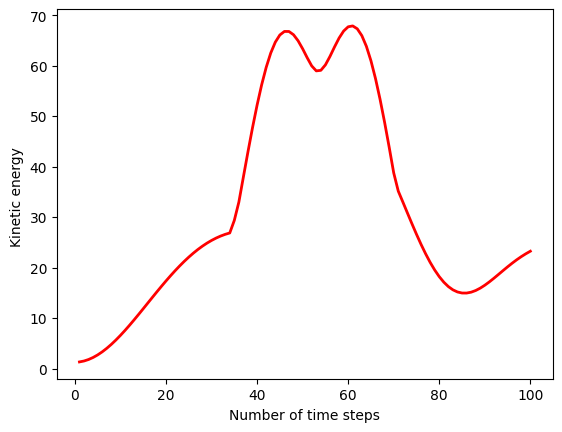

In [ ]:
import matplotlib.pyplot as plt
x=np.arange(1,num_steps+1)
plt.plot(x,y,color="red",linewidth=2,linestyle='-')
plt.xlabel("Number of time steps")
plt.ylabel("Kinetic energy ")
plt.show()


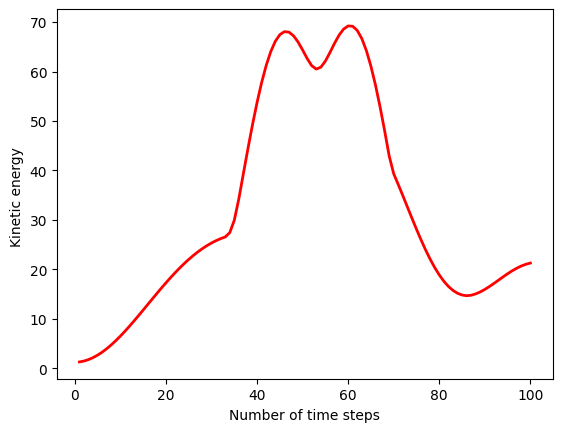

 Smaller dt makes the result more stable and particle motion more smoother. The second KE calculation (Velocity verlet method)
approximates KE better that the first (Euler method) . For small dt, the graphs are almost same because the Euler method used is a Symplectic Euler,
which uses the updated velocity and not the old one to calculate KE,hence integrating better, and thus closely resembling the Verlet scenario.
Halving dt roughly halves the Euler energy drift (first order). Verlet is better in absolute terms, but its gain is less clean than the ideal 1/4,
, because the spring force jumps at the cutoff r_c and at wall hits (see the dt study in the next cell).


In [ ]:
Y=np.zeros(num_steps)
pos_current=pos.copy()
vel_current=vel.copy()
F=None
def step_smooth(pos, vel, mass, dt, L, F_prev=None):
    if F_prev is None:
        F_prev = pair_forces(pos)
    a_prev = F_prev / mass[:, None]
    vel_half = vel + 0.5 * a_prev * dt
    pos_new = pos + vel_half * dt
    pos_new,vel_half=wall_reflection(pos_new, vel_half, L,e_input)
    F_new = pair_forces(pos_new)
    a_new = F_new / mass[:, None]
    vel_new = vel_half + 0.5 * a_new * dt
    return pos_new, vel_new, F_new
pos_new,vel_new,F_new=step_smooth(pos_current, vel_current, mass, dt, L, F_prev=None)
Y[0]=Kinetic_energy(mass,vel_new)
for i in range(1,num_steps):
    pos_new, vel_new, F_new= step_smooth(pos_new, vel_new, mass, dt, L, F_new)
    Y[i]=Kinetic_energy(mass,vel_new)

x=np.arange(1,num_steps+1)
plt.plot(x,Y,color="red",linewidth=2,linestyle='-')
plt.xlabel("Number of time steps")
plt.ylabel("Kinetic energy ")
plt.show()
print(''' Smaller dt makes the result more stable and particle motion more smoother. The second KE calculation (Velocity verlet method)
approximates KE better that the first (Euler method) . For small dt, the graphs are almost same because the Euler method used is a Symplectic Euler,
which uses the updated velocity and not the old one to calculate KE,hence integrating better, and thus closely resembling the Verlet scenario.''')
print('''Halving dt roughly halves the Euler energy drift (first order). Verlet is better in absolute terms, but its gain is less clean than the ideal 1/4,
, because the spring force jumps at the cutoff r_c and at wall hits (see the dt study in the next cell).''')

dt=0.05   euler , KE ranges from   2.8 to  68.0 | E_total drift = 21.657
dt=0.05   verlet, KE ranges from   2.7 to  69.8 | E_total drift = 6.000
dt=0.01   euler , KE ranges from   1.3 to  67.9 | E_total drift = 5.040
dt=0.01   verlet, KE ranges from   1.3 to  69.2 | E_total drift = 0.816
dt=0.001  euler , KE ranges from   1.2 to  68.7 | E_total drift = 0.516
dt=0.001  verlet, KE ranges from   1.2 to  68.6 | E_total drift = 0.175


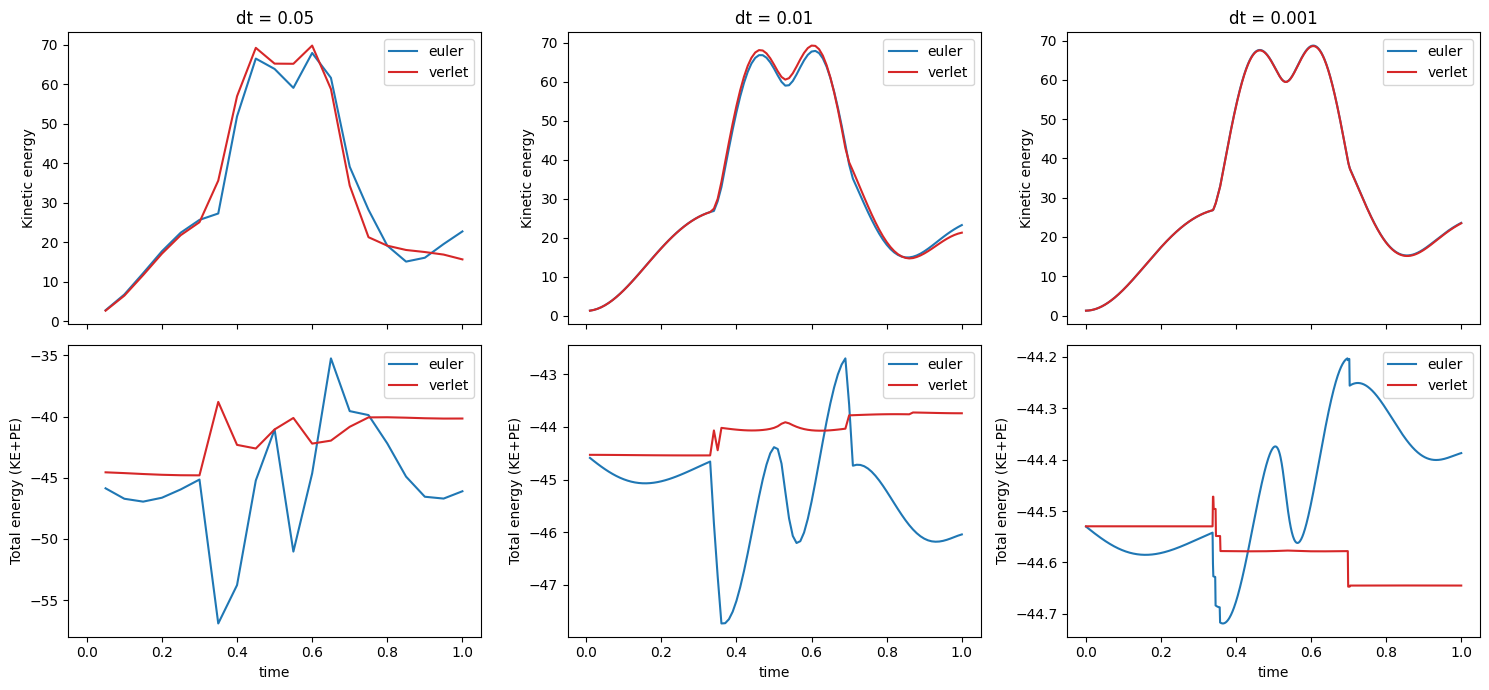

All particles stayed inside the box for every run.


In [ ]:
import matplotlib.pyplot as plt

def potential_energy(pos):
    """Spring PE shifted so V(r_c)=0, so it is continuous at the cutoff."""
    d, dist, nb = pairwise_dist(pos, r_c)
    V = (0.5*k*(dist - r0)**2 - 0.5*k*(r_c - r0)**2) * nb
    return 0.5*np.sum(V)                 # each pair appears twice in the NxN matrix

def run_study(dt, method, total_time=1.0):
    n = int(round(total_time/dt))
    p, v = pos.copy(), vel.copy()
    Fp = None
    KE, ETOT = [], []
    for _ in range(n):
        if method == "euler":
            p, v = step_once(p, v, mass, dt, L, e_input)
        else:
            p, v, Fp = step_smooth(p, v, mass, dt, L, Fp)
        assert ((p >= 0) & (p <= L)).all(), "particle escaped the box!"   # box check
        ke = Kinetic_energy(mass, v)
        KE.append(ke); ETOT.append(ke + potential_energy(p))
    return np.linspace(dt, n*dt, n), np.array(KE), np.array(ETOT)

dts = [0.05, 0.01, 0.001]
fig, ax = plt.subplots(2, len(dts), figsize=(15, 7), sharex=True)
for c, dt_ in enumerate(dts):
    for method, col in [("euler", "tab:blue"), ("verlet", "tab:red")]:
        t_, ke_, et_ = run_study(dt_, method)
        ax[0, c].plot(t_, ke_, color=col, label=method)
        ax[1, c].plot(t_, et_, color=col, label=method)
        print(f"dt={dt_:<6} {method:6}, KE ranges from {ke_.min():5.1f} to {ke_.max():5.1f} | E_total drift = {et_.max()-et_.min():.3f}")
    ax[0, c].set_title(f"dt = {dt_}"); ax[0, c].set_ylabel("Kinetic energy")
    ax[1, c].set_ylabel("Total energy (KE+PE)"); ax[1, c].set_xlabel("time")
    ax[0, c].legend(); ax[1, c].legend()
plt.tight_layout(); plt.show()
print("All particles stayed inside the box for every run.")

In [ ]:
print('''KE is not constant (it swaps with spring potential energy), but total KE+PE stays nearly flat for Verlet(for small dt) and drifts more for Euler, worst at large dt.
 Smaller dt reduces the drift for both.''')

KE is not constant (it swaps with spring potential energy), but total KE+PE stays nearly flat for Verlet(for small dt) and drifts more for Euler, worst at large dt.
 Smaller dt reduces the drift for both.


In [ ]:
#Collision and Verlet analysis
test_pos = np.array([[9.9, 4.0]])
test_vel = np.array([[10.0, 4.5]])
mass = np.array([1.0])
dt = 0.02
# Assume no interparticle forces
F_prev = np.array([[0.0, 0.0]])
a_prev = F_prev / mass[:, None]
# First half velocity update
vel_half = test_vel + 0.5 * a_prev * dt
# Position update
pos_new = test_pos + vel_half * dt
# Applying wall reflection
pos_new, vel_half = wall_reflection(
    pos_new, vel_half, L, e_input
)
# No interparticle forces assumed
F_new = np.array([[0.0, 0.0]])
a_new = F_new / mass[:, None]
# Complete velocity update
vel_new = vel_half + 0.5 * a_new * dt
print("Position after collision:", pos_new)
print("Velocity after collision:", vel_new)
#The correct position update algorithm
#time_taken_to_reach_wall=(10-9.9)/10=0.01 sec, implies in 0.02 seconds it would hit wall, return back to same x=9.9
pos_exact=[[9.9,4.09]]
position_error = round(np.linalg.norm(pos_new - pos_exact),2)
print('The correct x position for this collision should have been:',pos_exact)
print('Error in position(x):',position_error)

Position after collision: [[10.    4.09]]
Velocity after collision: [[-10.    4.5]]
The correct x position for this collision should have been: [[9.9, 4.09]]
Error in position(x): 0.1
